# 7. Nonlinear iteration: Python versus MATLAB

Run the Python test, then the MATLAB Live Script, then this notebook.
This notebook only reads saved results. It does not run either solver.

We compare the independently initialized grid/profiles, final circuit,
fields, beam states, full tracking arrays, and iteration history.
The efficiency **residual** is checked separately: because efficiency is
close to zero in this source model, its relative change can be sensitive
to roundoff. Efficiency itself is still compared between languages.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat

# Find pyKlyC whether the kernel starts in this folder or in the project.
current = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current, *current.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "large_signal_1d.py").is_file()
)
test_directory = project_directory / "test" / "7.nonlinear_iteration_test"
sys.path.insert(0, str(project_directory / "src"))

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True,
    "grid.color": "gray", "grid.linestyle": "--", "grid.alpha": 0.45,
})
np.set_printoptions(precision=6, linewidth=120)

In [2]:
inputs = loadmat(test_directory / "inputs.mat")
python = loadmat(test_directory / "python_results.mat")
matlab = loadmat(test_directory / "matlab_results.mat")
assert python["run_id"].item() == matlab["run_id"].item() == inputs["run_id"].item(), "Rerun both producers: these results belong to different exports."

names = set(python) - {"__header__", "__version__", "__globals__", "run_id"}
assert names == set(matlab) - {"__header__", "__version__", "__globals__", "run_id"}
rtol, atol = 1e-8, 1e-10

# Only these vectors/scalars may differ in row/column orientation.
vectors = set("zi z U0 I0 s betae dt wp nn iterationsuc SCmethod effendflag "
              "iterations SCmethods drivefactors skipped_iterations effend_history "
              "residential_history residentialel_history Esz0 Emz0 Esmz0 IzDC QQDC effe "
              "vez gamaz B Vnc Vnp Vin flagVnc Utn ttn Y Yflag Pe IzDCr QQDCr".split())
exact = set("nn iterationsuc SCmethod iterations SCmethods skipped_iterations Y Yflag".split())

## 1. Compare arrays and iteration decisions

Complex values are compared directly, including their phase. Matrix shapes
must match. Python's active indices `Y` are zero-based; MATLAB's are
converted for comparison. Unused `Zn`/`Vn` entries are infinite markers:
their masks and signs must agree, rather than treating them as positions.
`Esz0` is space charge and `Esmz0` is total DC in both exported files.

In [3]:
for name in sorted(names - {"residentialel_history"}):
    a = python[name]
    b = matlab[name]
    if name == "Y":
        b = b - 1
    if name in vectors:
        a, b = a.reshape(-1), b.reshape(-1)
    assert a.shape == b.shape, f"{name}: shape mismatch {a.shape} vs {b.shape}"
    np.testing.assert_array_equal(np.isfinite(a), np.isfinite(b), err_msg=name)
    if name in exact:
        np.testing.assert_array_equal(a, b, err_msg=name)
    else:
        np.testing.assert_allclose(a, b, rtol=rtol, atol=atol, equal_nan=True, err_msg=name)
    finite = np.isfinite(a) & np.isfinite(b)
    error = np.max(abs(a[finite] - b[finite])) if np.any(finite) else 0.0
    print(f"{name:24s} max absolute difference = {error:.3e}")

B                        max absolute difference = 1.053e-16
C3                       max absolute difference = 5.100e-16
Emz                      max absolute difference = 0.000e+00
Emz0                     max absolute difference = 0.000e+00
Esmz                     max absolute difference = 5.045e-18
Esmz0                    max absolute difference = 3.154e-17
Esz                      max absolute difference = 5.045e-18
Esz0                     max absolute difference = 3.154e-17
Esz00                    max absolute difference = 2.711e-20
I0                       max absolute difference = 0.000e+00
Iz                       max absolute difference = 1.285e-14
IzDC                     max absolute difference = 0.000e+00
IzDCr                    max absolute difference = 0.000e+00
Izr                      max absolute difference = 2.859e-14
Mc                       max absolute difference = 6.939e-18
Pe                       max absolute difference = 8.882e-16
QQ                      

## 2. Check the efficiency-residual formula in each language

The comparison efficiency starts at zero and is reset to zero when switching
from local to global space charge. Otherwise the preceding evaluated
efficiency is retained. No artificial denominator floor is inserted.

In [4]:
for label, data in [("Python", python), ("MATLAB", matlab)]:
    eff = data["effend_history"].ravel()
    modes = data["SCmethods"].ravel()
    previous = np.r_[0.0, eff[:-1]]
    switched = np.flatnonzero(modes[1:] != modes[:-1]) + 1
    previous[switched] = 0.0
    with np.errstate(divide="ignore", invalid="ignore"):
        expected = abs((previous - eff) / eff)
    np.testing.assert_allclose(data["residentialel_history"].ravel(), expected,
                               rtol=1e-12, atol=1e-12, equal_nan=True)
    print(label, "efficiency-residual formula: PASS")

Python efficiency-residual formula: PASS
MATLAB efficiency-residual formula: PASS


## 3. Overlay the two results

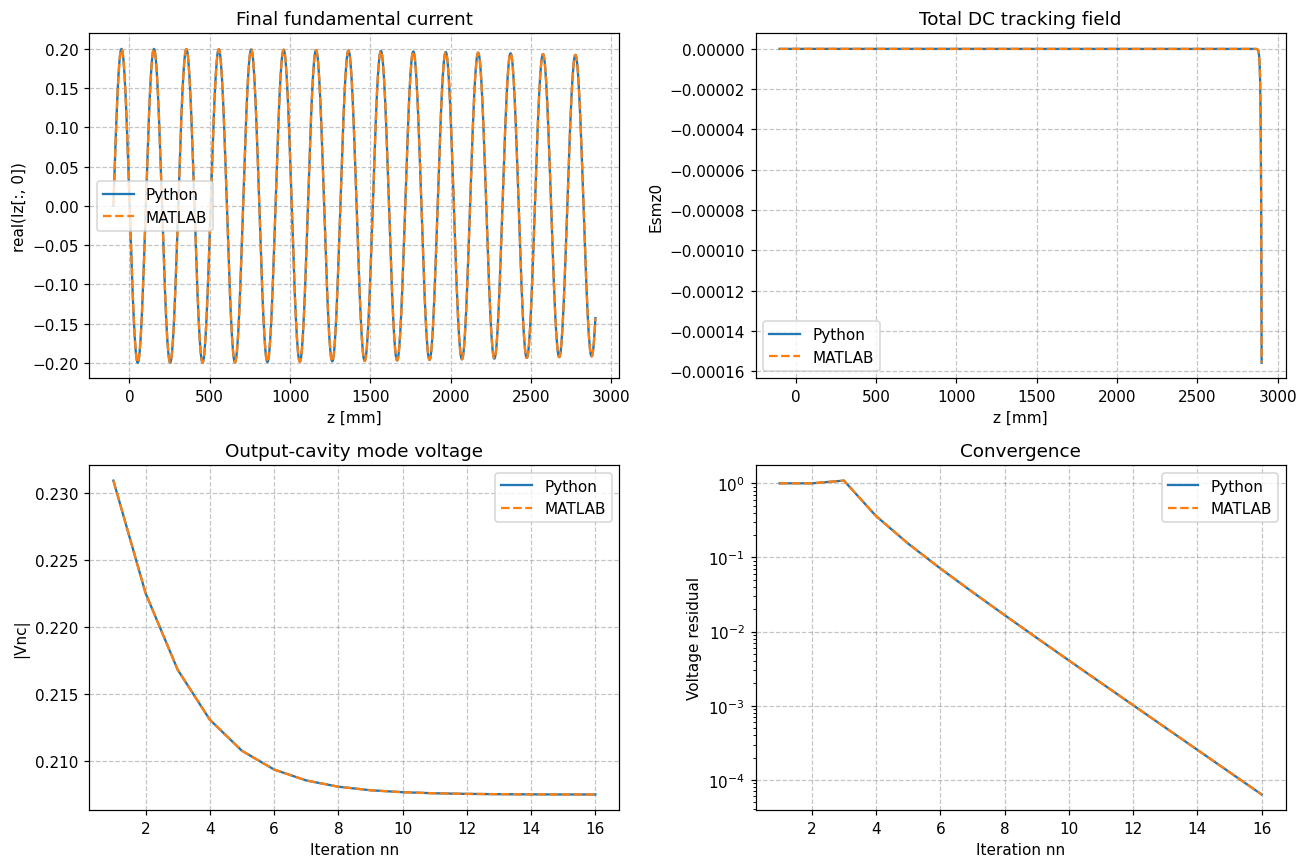

PASS: Python and MATLAB agree for this exported case.


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for label, data, style in [("Python", python, "-"), ("MATLAB", matlab, "--")]:
    zi = data["zi"].ravel()
    nn = data["iterations"].ravel()
    axes[0, 0].plot(zi, data["Iz"][:, 0].real, style, label=label)
    axes[0, 1].plot(zi, data["Esmz0"].ravel().real, style, label=label)
    axes[1, 0].plot(nn, abs(data["Vnc_history"][:, -1]), style, label=label)
    axes[1, 1].semilogy(nn, np.maximum(data["residential_history"].ravel(), 1e-15), style, label=label)
axes[0, 0].set(xlabel="z [mm]", ylabel="real(Iz[:, 0])", title="Final fundamental current")
axes[0, 1].set(xlabel="z [mm]", ylabel="Esmz0", title="Total DC tracking field")
axes[1, 0].set(xlabel="Iteration nn", ylabel="|Vnc|", title="Output-cavity mode voltage")
axes[1, 1].set(xlabel="Iteration nn", ylabel="Voltage residual", title="Convergence")
for axis in axes.flat:
    axis.legend()
plt.tight_layout()
plt.show()
print("PASS: Python and MATLAB agree for this exported case.")